## TEMPEST L2 Occam's inversion

In [10]:
using PyPlot, DelimitedFiles, Random, Statistics, HiQGA
cd(@__DIR__)

## Model discretization

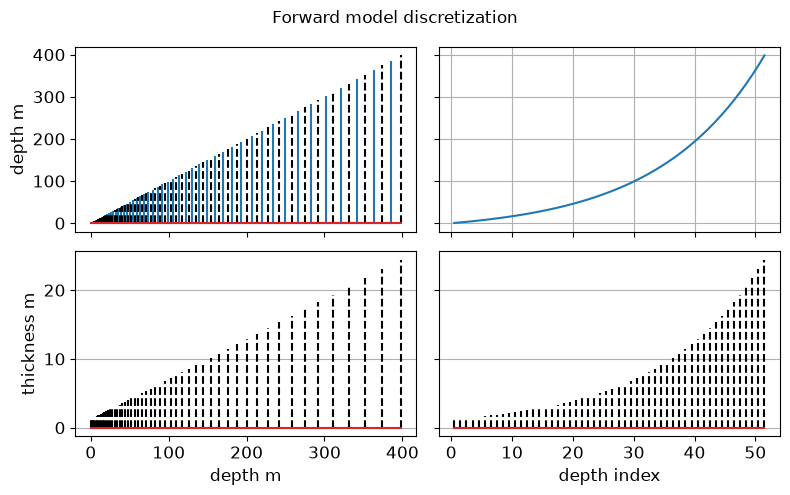

In [11]:
# model fixed parts, i.e., air
zfixed   = [-1e5]
ρfixed   = [1e12]
# Note that the receiver and transmitter need to be in layer 1
zstart = 0.0
extendfrac, dz = 1.06, 1.25
nlayers = 52
zall, znall, zboundaries = transD_GP.setupz(zstart, extendfrac, dz=dz, n=nlayers, showplot=true)
z, ρ, nfixed = transD_GP.makezρ(zboundaries; zfixed=zfixed, ρfixed=ρfixed)
# Rx, Tx geometry geometry parameters for tempest
zTx = -120
zRx = -82
x_rx = -113.0
y_rx = 0.
rx_roll = 0.
rx_pitch = 2.
rx_yaw = 0.
tx_roll = 0.
tx_pitch = 0.
tx_yaw = 0.
# read waveform, window times, noise
include("../00_required/tempest_electronics_halt.jl");

## create total field TEMPEST operator (required for nuisance inversion)

In [12]:
calcjacobian = true # needed for gradient descent
vectorsum = false # if true, invert field amplitude in XZ plane
tempest = transD_GP.TEMPEST1DInversion.Bfield(;
    zTx = zTx, zRx = zRx, x_rx = x_rx, y_rx = y_rx,
    rx_roll = rx_roll, rx_pitch = rx_pitch, rx_yaw = rx_yaw,
    tx_roll = tx_roll, tx_pitch = tx_pitch, tx_yaw = tx_yaw,
	ramp = ramp, times = times,
	z=z,
	ρ=ρ,
	addprimary = true, #this ensures that the geometry update actually changes everything that needs to be
    vectorsum,   # amplitude only inversions
    calcjacobian # for gradientbased inversion
);

## Construct synthetic model and plot data

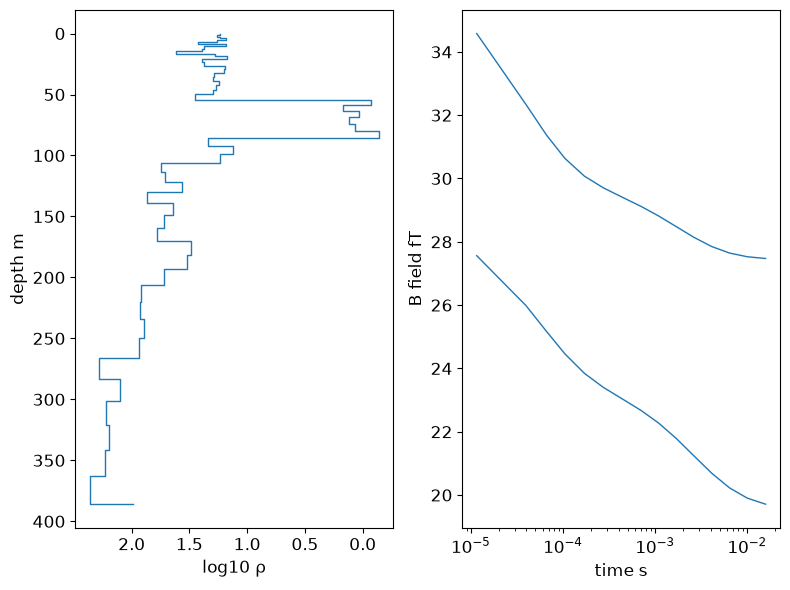

In [13]:
# fill in detail in ohm-m
ρ[(z.>=zstart) .& (z.<50)] .= 20.
ρ[(z.>=50) .&(z.<80)]      .= 1
ρ[(z.>=80) .&(z.<100)]     .= 20
ρ[(z.>=100) .&(z.<200)]    .= 50
ρ[(z.>=200) .&(z.<250)]    .= 80
ρ[(z.>=250)]               .= 150
# add jitter to model in log10 domain
Random.seed!(11)
ρ = 10 .^(0.1*randn(length(ρ)) + log10.(ρ))
# plot before adding noise
transD_GP.TEMPEST1DInversion.plotmodelfield!(tempest, log10.(ρ[2:end]));

## compute noisy data to invert

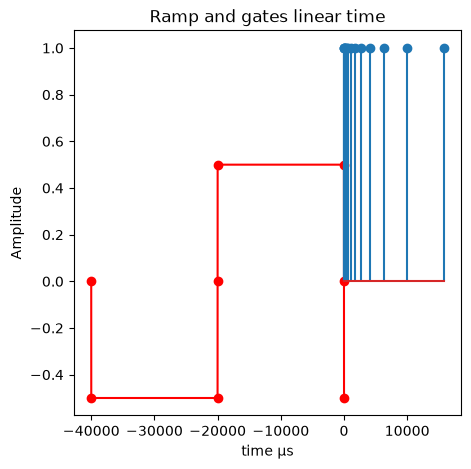

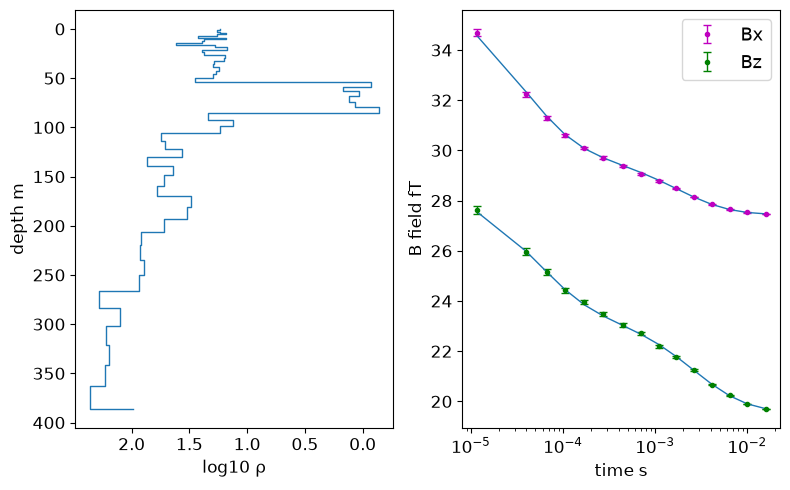

In [14]:
transD_GP.TEMPEST1DInversion.makenoisydata!(tempest, log10.(ρ[2:end]),
                        noisefracx = 0.02, noisefracz = 0.02,
                        halt_X = Hx_add_noise, halt_Z = Hz_add_noise,
                        units = 1e-15)
Torig = deepcopy(tempest);

## Gradient descent options

In [15]:
# for gradient descent, all model values are in log10 conductivity
# create empty log10 conductivity arrays for start and background
σstart      = -2*ones(length(zall))
σ0          = -2*ones(length(zall)) # prior model
lo          = -3      # log10 min conductivity
hi          = 1       # log10 max conductivity
λ²min       = 0       # min log10 of Tikhonov parameter
λ²max       = 7.      # max log10 of Tikhonov parameter
ntries      = 10      # how many max tries between λ²min, λ²max
β²          = 0.001   # what fraction of roughness penalty to use to enforce a penalty in deviations from background
knownvalue  = 0.7     # cutoff to start next Gauss-Newton step
nstepsmax   = 20      # Gauss-Newton steps
regtype     = :R1     # :R1 is first difference regularization, :R2 is two succesive first differences## nuisance stuff
if tempest.vectorsum
    nustart  = [zRx-1, x_rx-1]
    nubounds = [zRx-3   zRx+3
                x_rx-3 x_rx+3];
else
    nustart  = [zRx-1, x_rx+1, rx_pitch+0.5]
    nubounds = [zRx-3      zRx+3
                x_rx-3     x_rx+3
                rx_pitch-1.5 rx_pitch+1.5];
end;

## Do the inversion!

In [16]:
tempest = deepcopy(Torig);
m, nu, χ², χ²nu, λ², idx = transD_GP.gradientinv(σstart, σ0, nustart, tempest;
                            # Occam stuff
                            λ²min, λ²max, β², ntries, knownvalue,
                            lo, hi, regtype, nstepsmax,
                            # optim stuff
                            nubounds,
                            ntriesnu = 5,
                            boxiters = 2,
                            );
aem = tempest;

[ Info: iteration: 1 χ²: 20565.495037645174 target: 30
[ Info: iteration: 2 χ²: 9890.54530884989 target: 30
[ Info: iteration: 3 χ²: 2670.3493432694745 target: 30
[ Info: iteration: 4 χ²: 961.6662305306384 target: 30
[ Info: iteration: 5 χ²: 183.63062268521708 target: 30
[ Info: iteration: 6 χ²: 43.38246019962826 target: 30
[ Info: iteration: 7 χ²: 30.00000000000029 target: 30


## Plot each iteration of descent

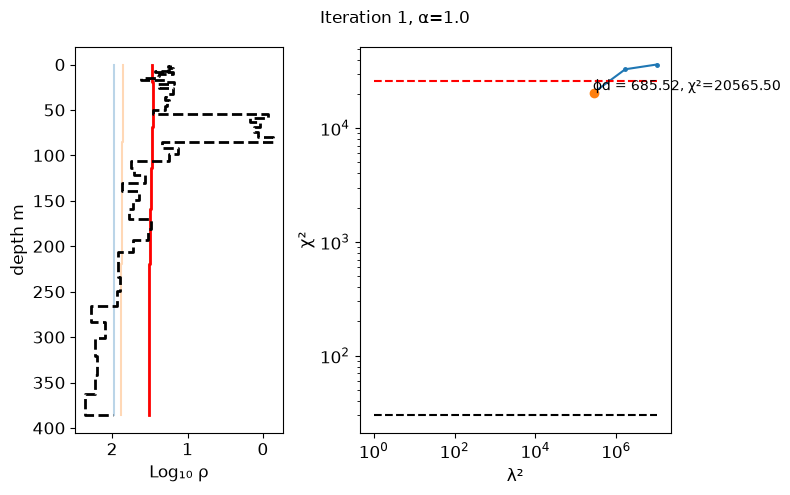

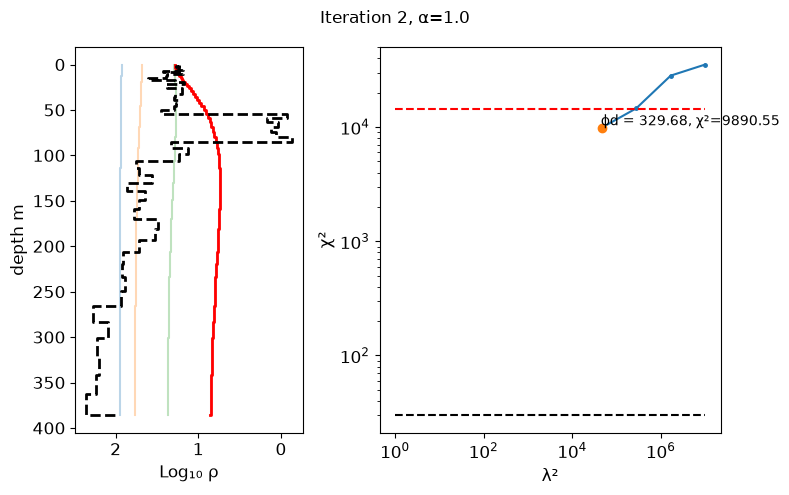

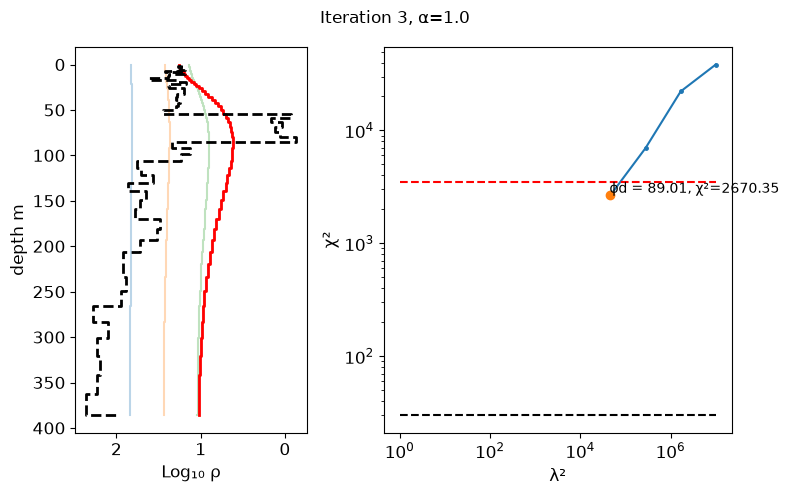

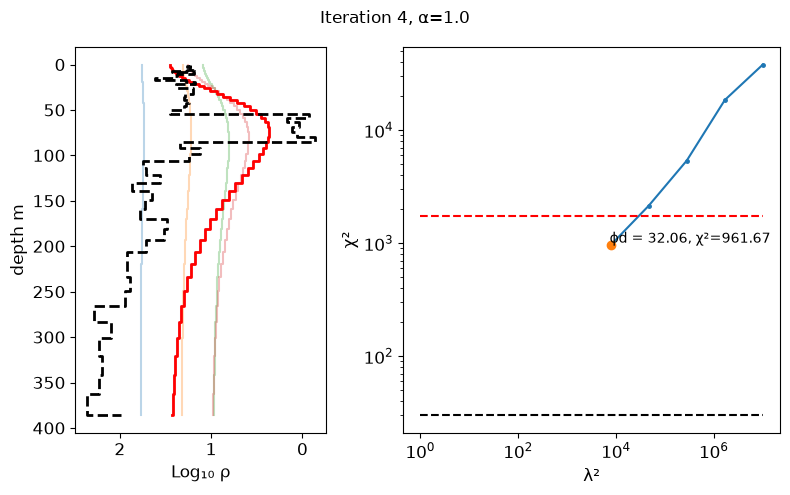

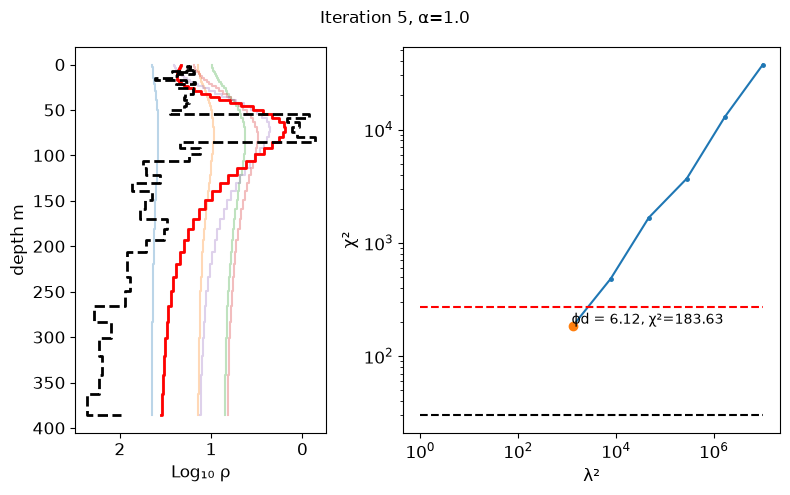

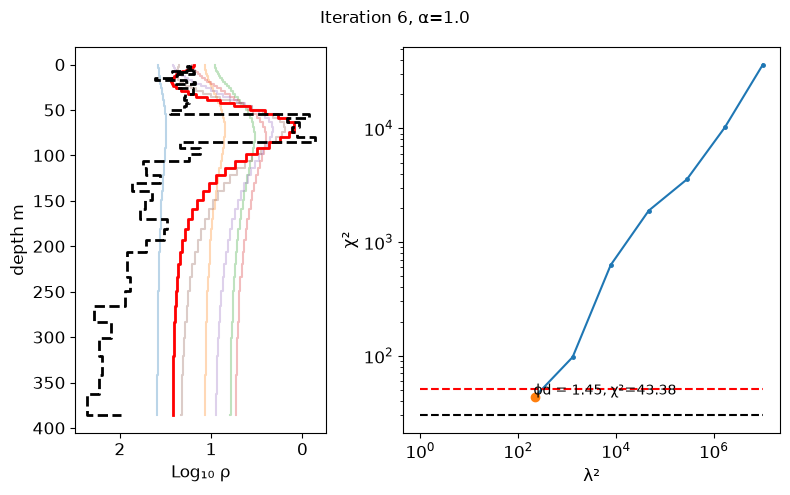

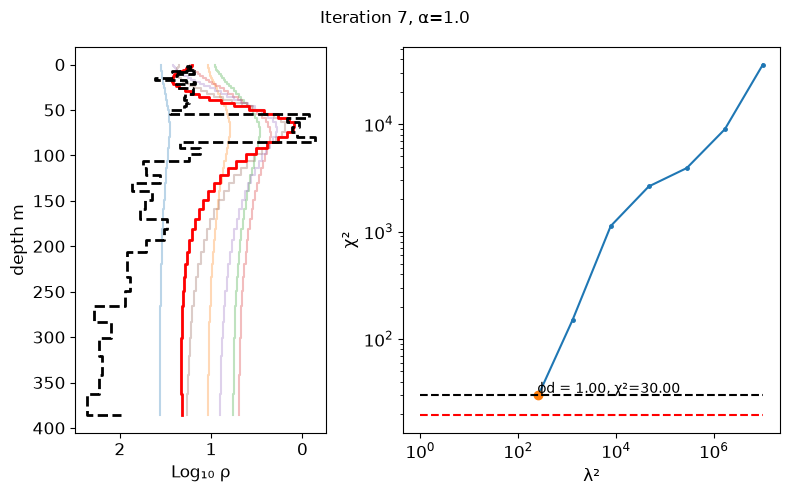

In [17]:
# inner plots for each outer iteration
using Printf
alpha = 0.3
ndata = length(aem.res)
for (i, mi) in enumerate(m)
    f, s = plt.subplots(1, 2, gridspec_kw=Dict("width_ratios" => [1,1.5]),
        figsize=(8,5))
    for ii in 1:length(χ²[i])
        s[1].step(-mi[ii], aem.z[2:end], alpha=alpha)
    end
    s[1].step(-mi[idx[i]], aem.z[2:end], color="r", linewidth=2)
    s[1].step(log10.(ρ[2:end]), z[2:end], color="k", linewidth=2, linestyle="--")
    s[1].set_ylabel("depth m")
    s[1].set_xlabel("Log₁₀ ρ")
    s[1].invert_yaxis()
    s[1].invert_xaxis()
    hps = hcat(λ²[i]...)'
    sortedλidx = sortperm(hps[:,1])
    sortedαidx = sortperm(hps[:,2])
    s[2].loglog(hps[sortedλidx,1], χ²[i][sortedλidx], ".-", markersize=5)
    s[2].plot(hps[idx[i],1], χ²[i][idx[i]], "o" )
    s[2].text(.95hps[idx[i],1], 1.05χ²[i][idx[i]], "ϕd = $(@sprintf("%.2f", χ²[i][idx[i]]/ndata)), χ²=$(@sprintf("%.2f", χ²[i][idx[i]]))" )
    s[2].plot(10. .^[λ²min, λ²max], [ndata, ndata], "--k")
    target = knownvalue*χ²nu[i]
    s[2].plot(10. .^[λ²min, λ²max], [target, target], "--r")
    s[2].set_ylabel("χ²")
    s[2].set_xlabel("λ²")
    plt.suptitle("Iteration $i, α=$(hps[idx[i],2])")
    transD_GP.nicenup(gcf(), fsize=12)
end

## Plots for best in each outer iteration

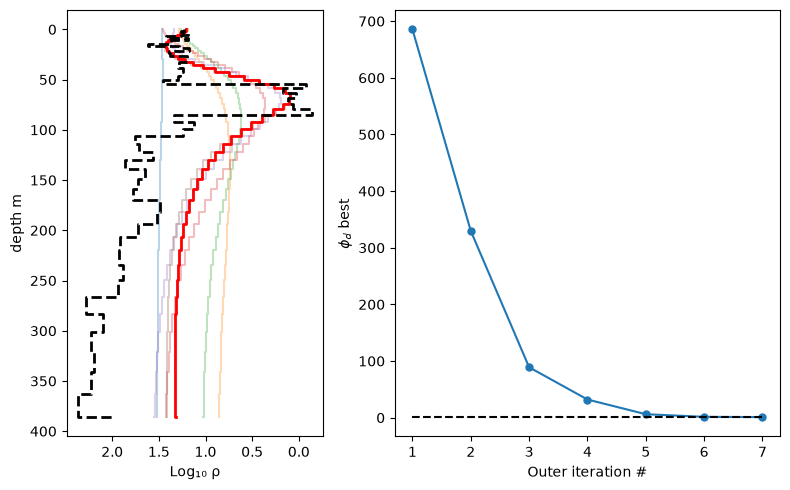

In [18]:
f, s = plt.subplots(1, 2, gridspec_kw=Dict("width_ratios" => [1,1.5]),
        figsize=(8,5))
alpha = 0.3
χ²best = zeros(0)
idxlast = length(m)
ndata = length(aem.res)
for (i, mi) in enumerate(m)
    s[1].step(-mi[idx[i]], aem.z[2:end], alpha=alpha)
    push!(χ²best, minimum(χ²[i]))
    i == idxlast && break
end
s[1].step(-m[idxlast][idx[idxlast]], aem.z[2:end], color="r", linewidth=2)
s[1].step(log10.(ρ[2:end]), z[2:end], color="k", linewidth=2, linestyle="--")
s[1].invert_yaxis()
s[1].invert_xaxis()
s[1].set_ylabel("depth m")
s[1].set_xlabel("Log₁₀ ρ")
s[2].plot(1:idxlast, χ²best/ndata, ".-", ms=10)
s[2].plot([1, idxlast], [1, 1], "--k")
s[2].set_xlabel("Outer iteration #")
s[2].set_ylabel(L"ϕ_d"*" best")
f.tight_layout()

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*